### Task 1: Load MNIST and Train Baseline CNN

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Set device and random seed
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.manual_seed_all(42)

# Load Data
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

# Define Baseline CNN (two convolution layers + two fully-connected layers)
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train Baseline Model
epochs = 2
for epoch in range(epochs):
    model.train()
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
    print(f"Epoch {epoch+1}/{epochs} completed.")

# Evaluate baseline model on clean data
def evaluate_clean(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data, target in loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            _, predicted = torch.max(output.data, 1)
            total += target.size(0)
            correct += (predicted == target).sum().item()
    return 100 * correct / total

clean_acc = evaluate_clean(model, test_loader)
print(f"Clean Test Accuracy: {clean_acc:.2f}%")

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.84MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 155kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.47MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.94MB/s]


Epoch 1/2 completed.
Epoch 2/2 completed.
Clean Test Accuracy: 98.63%


### Tasks 2 & 3: Implement FGSM & PGD Attacks and Evaluate Baseline

In [2]:
# FGSM Attack
def fgsm_attack(image, epsilon, data_grad):
    sign_data_grad = data_grad.sign()
    perturbed_image = image + epsilon * sign_data_grad
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

# PGD Attack (L_infinity)
def pgd_attack(model, image, target, epsilon, alpha, num_iter):
    perturbed_image = image.clone().detach() + torch.FloatTensor(*image.shape).uniform_(-epsilon, epsilon).to(device)
    perturbed_image = torch.clamp(perturbed_image, 0, 1).requires_grad_(True)

    for i in range(num_iter):
        output = model(perturbed_image)
        loss = criterion(output, target)
        model.zero_grad()
        loss.backward()

        with torch.no_grad():
            data_grad = perturbed_image.grad.data
            perturbed_image = perturbed_image + alpha * data_grad.sign()
            # Projection step
            eta = torch.clamp(perturbed_image - image, min=-epsilon, max=epsilon)
            perturbed_image = torch.clamp(image + eta, min=0, max=1).detach().requires_grad_(True)

    return perturbed_image

# Evaluation loop for adversarial attacks
def evaluate_adversarial(model, loader, attack_type, epsilon):
    model.eval()
    correct = 0
    total = 0

    for data, target in loader:
        data, target = data.to(device), target.to(device)
        data.requires_grad = True

        output = model(data)
        loss = criterion(output, target)
        model.zero_grad()
        loss.backward()

        if attack_type == 'FGSM':
            perturbed_data = fgsm_attack(data, epsilon, data.grad.data)
        elif attack_type == 'PGD':
            alpha = epsilon / 4 if epsilon > 0 else 0
            perturbed_data = pgd_attack(model, data, target, epsilon, alpha, num_iter=10)

        with torch.no_grad():
            output = model(perturbed_data)
            _, predicted = torch.max(output.data, 1)
            total += target.size(0)
            correct += (predicted == target).sum().item()

    return 100 * correct / total

epsilons = [0.05, 0.10, 0.20, 0.30]
fgsm_accuracies = []
pgd_accuracies = []

for eps in epsilons:
    fgsm_acc = evaluate_adversarial(model, test_loader, 'FGSM', eps)
    pgd_acc = evaluate_adversarial(model, test_loader, 'PGD', eps)
    fgsm_accuracies.append(fgsm_acc)
    pgd_accuracies.append(pgd_acc)
    print(f"Epsilon: {eps:.2f} | FGSM Accuracy: {fgsm_acc:.2f}% | PGD Accuracy: {pgd_acc:.2f}%")

Epsilon: 0.05 | FGSM Accuracy: 95.90% | PGD Accuracy: 95.33%
Epsilon: 0.10 | FGSM Accuracy: 88.56% | PGD Accuracy: 82.26%
Epsilon: 0.20 | FGSM Accuracy: 49.78% | PGD Accuracy: 7.74%
Epsilon: 0.30 | FGSM Accuracy: 12.09% | PGD Accuracy: 0.00%


### Task 4: Display Clean vs FGSM Adversarial Digits (ε = 0.20)

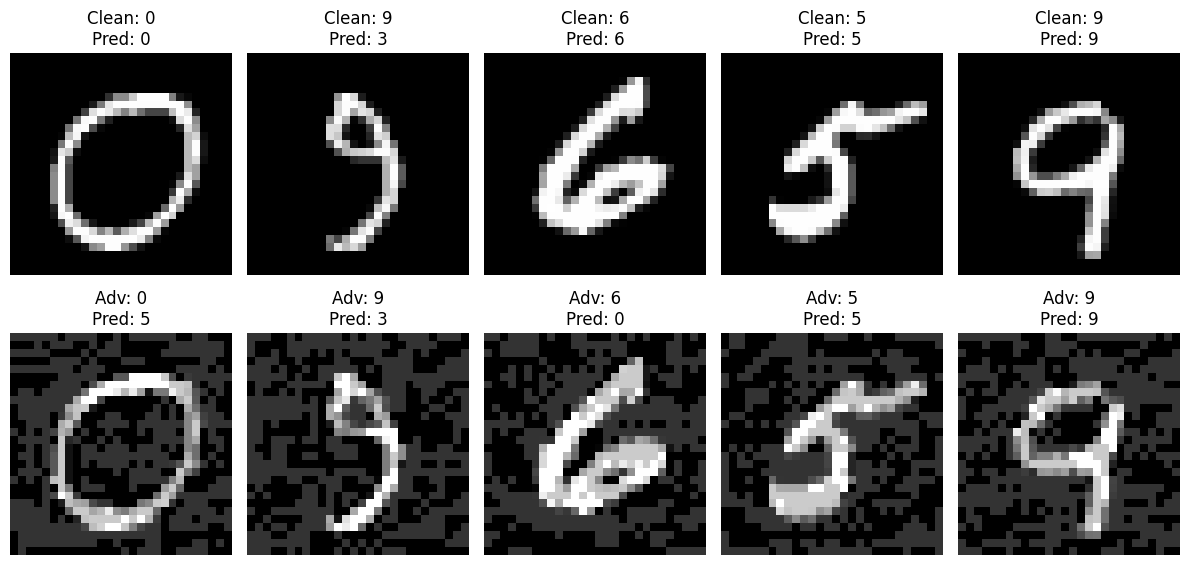

In [3]:
model.eval()
images, labels = next(iter(DataLoader(test_dataset, batch_size=5, shuffle=True)))
images, labels = images.to(device), labels.to(device)
images.requires_grad = True

output = model(images)
loss = criterion(output, labels)
model.zero_grad()
loss.backward()

perturbed_images = fgsm_attack(images, 0.20, images.grad.data)
with torch.no_grad():
    outputs_clean = model(images)
    _, preds_clean = torch.max(outputs_clean, 1)
    outputs_adv = model(perturbed_images)
    _, preds_adv = torch.max(outputs_adv, 1)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i in range(5):
    # Clean display
    axes[0, i].imshow(images[i].cpu().detach().squeeze(), cmap='gray')
    axes[0, i].set_title(f"Clean: {labels[i].item()}\nPred: {preds_clean[i].item()}")
    axes[0, i].axis('off')

    # Adversarial display
    axes[1, i].imshow(perturbed_images[i].cpu().detach().squeeze(), cmap='gray')
    axes[1, i].set_title(f"Adv: {labels[i].item()}\nPred: {preds_adv[i].item()}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

### Task 5: Adversarial Training

In [4]:
adv_model = BaselineCNN().to(device)
adv_optimizer = optim.Adam(adv_model.parameters(), lr=0.001)

# Adversarial fine-tuning (50:50 clean/FGSM ε=0.20)
for epoch in range(2):
    adv_model.train()
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)

        # Split batch into two halves
        half_batch = data.size(0) // 2
        clean_data = data[:half_batch]
        adv_data_orig = data[half_batch:].clone().detach()
        adv_data_orig.requires_grad = True

        # Generate FGSM perturbations
        out_for_grad = adv_model(adv_data_orig)
        loss_for_grad = criterion(out_for_grad, target[half_batch:])
        adv_model.zero_grad()
        loss_for_grad.backward()
        perturbed_half = fgsm_attack(adv_data_orig, 0.20, adv_data_orig.grad.data)

        # Recombine batches
        mixed_data = torch.cat([clean_data, perturbed_half], dim=0)

        adv_optimizer.zero_grad()
        mixed_outputs = adv_model(mixed_data)
        loss = criterion(mixed_outputs, target)
        loss.backward()
        adv_optimizer.step()
    print(f"Adv-Training Epoch {epoch+1}/2 completed.")

# Re-evaluate robust model
adv_clean_acc = evaluate_clean(adv_model, test_loader)
adv_fgsm_acc_20 = evaluate_adversarial(adv_model, test_loader, 'FGSM', 0.20)
adv_pgd_acc_20 = evaluate_adversarial(adv_model, test_loader, 'PGD', 0.20)

Adv-Training Epoch 1/2 completed.
Adv-Training Epoch 2/2 completed.


### Task 6: Visualize and Tabulate Results

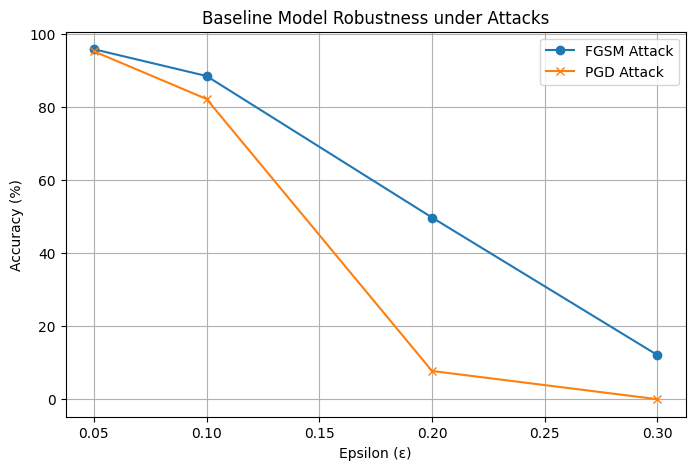

,Metric (at ε = 0.20),Baseline Model (%),Adversarially Trained Model (%)
0,Clean Accuracy,98.63,98.54
1,FGSM Accuracy,49.78,91.85
2,PGD Accuracy,7.74,14.50


In [5]:
# Plot accuracy vs Epsilon for Baseline Model
plt.figure(figsize=(8, 5))
plt.plot(epsilons, fgsm_accuracies, marker='o', label='FGSM Attack')
plt.plot(epsilons, pgd_accuracies, marker='x', label='PGD Attack')
plt.title('Baseline Model Robustness under Attacks')
plt.xlabel('Epsilon (ε)')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.legend()
plt.show()

# Build comparison table
results_data = {
    'Metric (at ε = 0.20)': ['Clean Accuracy', 'FGSM Accuracy', 'PGD Accuracy'],
    'Baseline Model (%)': [f"{clean_acc:.2f}", f"{fgsm_accuracies[2]:.2f}", f"{pgd_accuracies[2]:.2f}"],
    'Adversarially Trained Model (%)': [f"{adv_clean_acc:.2f}", f"{adv_fgsm_acc_20:.2f}", f"{adv_pgd_acc_20:.2f}"]
}
df_results = pd.DataFrame(results_data)
display(df_results)